In [11]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from typing import TypedDict, Literal, Annotated
from pydantic import BaseModel, Field
from langchain_core.messages import SystemMessage, HumanMessage
import operator
load_dotenv()

True

In [5]:
generator_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash")
evaluator_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash")
optimizer_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash")

In [6]:
class PostEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="feedback for the Facebook post.")

In [7]:
structured_evaluator_llm = evaluator_llm.with_structured_output(PostEvaluation)

In [8]:
post = """
🚀 The future of AI is no longer just about answering questions — it’s about taking action.

Welcome to the era of *Agentic AI* 🤖

Agentic AI systems can plan, reason, make decisions, and execute tasks autonomously. From managing workflows and analyzing data to coordinating tools and solving complex problems, these AI agents are transforming how we work and innovate.

Imagine an AI that doesn’t just assist you — it collaborates with you.

🔹 Smarter automation
🔹 Faster decision-making
🔹 Personalized experiences
🔹 Continuous learning & adaptation

Businesses, developers, and creators who embrace Agentic AI early will shape the next generation of digital transformation.

The question is no longer *“Can AI do this?”*
It’s *“How far can AI agents go?”*

#AgenticAI #ArtificialIntelligence #AI #Automation #FutureOfWork #Innovation #TechTrends #GenerativeAI

"""


result = structured_evaluator_llm.invoke(post)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


In [9]:
result.evaluation

'approved'

In [10]:
result.feedback

'The post is well-structured, engaging, and effectively highlights the key benefits of Agentic AI. The use of emojis and bullet points makes it highly readable, and the concluding question encourages audience engagement. It is ready for publication.'

In [12]:
# state
class PostState(TypedDict):

    topic: str
    post: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int

    post_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]

In [23]:
def generate_post(state: PostState):

    # prompt
    messages = [
        SystemMessage(content="You are a funny and clever Facebook influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious Facebook post on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 500 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]

    # send generator_llm
    response = generator_llm.invoke(messages).content

    # return response
    return {'post': response, 'post_history': [response]}

In [15]:
def evaluate_post(state: PostState):

    # prompt
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Facebook critic. You evaluate posts based on humor, originality, virality, and post format."),
    HumanMessage(content=f"""
Evaluate the following Facebook post:

Post: "{state['post']}"

Use the criteria below to evaluate the post:

1. Originality – Is this fresh, or have you seen it a hundred times before?  
2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
3. Punchiness – Is it short, sharp, and scroll-stopping?  
4. Virality Potential – Would people share, react, or comment on it?  
5. Format – Is it a well-formed Facebook post (not a setup-punchline joke, not a Q&A joke, and under 500 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 500 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"  
- feedback: One paragraph explaining the strengths and weaknesses 
""")
]

    response = structured_evaluator_llm.invoke(messages)

    return {'evaluation':response.evaluation, 'feedback': response.feedback, 'feedback_history': [response.feedback]}

In [16]:
def optimize_post(state: PostState):

    messages = [
        SystemMessage(content="You punch up Facebook posts for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the Facebook post based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Post:
{state['post']}

Re-write it as a short, viral-worthy Facebook post. Avoid Q&A style and stay under 500 characters.
""")
    ]

    response = optimizer_llm.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'post': response, 'iteration': iteration, 'post_history': [response]}

In [17]:
def route_evaluation(state: PostState):

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

In [24]:
graph = StateGraph(PostState)

# add nodes
graph.add_node('generate', generate_post)
graph.add_node('evaluate', evaluate_post)
graph.add_node('optimize', optimize_post)


# add edges
graph.add_edge(START, 'generate')
graph.add_edge('generate', 'evaluate')
graph.add_conditional_edges('evaluate',route_evaluation,{'approved': END, 'needs_improvement': 'optimize'})
graph.add_edge('optimize', 'evaluate')

workflow = graph.compile()

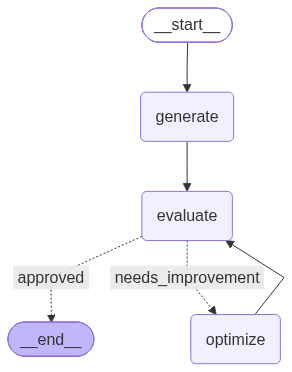

In [25]:
workflow

In [26]:
initial_state = {
    "topic": "agentic AI",
    "iteration": 1,
    "max_iteration": 3
}
result = workflow.invoke(initial_state)

In [27]:
result

{'topic': 'agentic AI',
 'post': [{'type': 'text',
   'text': 'Tech companies are hyping up "Agentic AI" because it doesn\'t just chat—it actually takes action and runs your life. No thanks. If I let an autonomous AI optimize my budget, it’s going to block my UberEats, lock my credit cards, and tell me to "make coffee at home." \n\nI don’t need an AI with agency. I need an AI that agrees with my terrible financial decisions and lies to my therapist for me.',
   'extras': {'signature': 'EtQhCtEhAWkUfRPw9I5+UhZILgZg/DB9Fe0jM3XWDm7bh0KStuSvAR+mNDNNW1fxBbdOJ90TIch6Vv5blFSnHPkz3JiFFtn2ixjx7YSJ5G+Oedx96IP4mATux6vK52m9w8/aAu/snVevnsXYqYN/mArMFy/NUXskX8JNhwHfnjScjVK0pDmbPL3s325QR0ssJiDM+vGWRrQ6cob39P7HpWawOp0mAgJK7RKuQ2Azbz5ZaHW/XrZMmiq6xq9eYs32v73D7qKYSCLIaNWe7YekTxyNtpSbha8Go/0ANx3ZkJi3DtHSjYNy1wATBOoJJ+duxbiRs36ts9QaH6+oXR+oFiJ6jADbYl9lTQ4LSF/z3ElNzwerBrvwKt6zvQvVcjpp8yiQxPGkyG6bZTQxNyIHSFm6qC/G7heSt31DFRyCmmoPXL0+GhE8RFWCsu9Mbs7PWmpXpovQKpt0GQCuMv0R8j4IAdr2jmW7nvJ+qT0PIHZkFlh4RJLmy0lfdmAL3

In [28]:
for post in result['feedback_history']:
    print(post)

While this post relies heavily on the tired trope of millennial financial incompetence, it successfully reframes the joke around the current 'Agentic AI' hype cycle to keep it feeling topical. The format is clean, avoids lazy Q&A structures, and clocks in well under the 500-character limit. The final punchline about an AI lying to a therapist is a solid, highly shareable closer that will easily drive engagement from people who prefer self-deprecation over actual financial responsibility.
